In [1]:
# Importar a biblioteca pandas para manipulação de dados
import pandas as pd

# Simulação de dados que vieram da nossa base de dados MySQL (Projeto 2)
dados_vendas = {
    'ID_Transacao': ['T1001', 'T1002', 'T1003', 'T1004', 'T1005', 'T1006', 'T1007', 'T1008', 'T1009', 'T1010'],
    'ID_Cliente': ['C0001', 'C0002', 'C0001', 'C0003', 'C0004', 'C0005', 'C0002', 'C0006', 'C0007', 'C0001'],
    'Data_Pedido': ['2025-07-10', '2025-04-07', '2025-01-28', '2025-09-06', '2025-01-29', '2025-11-27', '2025-08-08', '2025-12-30', '2025-08-23', '2025-11-28'],
    'Valor_Total': [3200.00, 350.00, 2800.00, 700.00, 2200.00, 2800.00, 4500.00, 700.00, 1500.00, 1700.00]
}

# Criando o DataFrame (a tabela no Python)
df_transacoes = pd.DataFrame(dados_vendas)

# Converter a coluna de data para o formato de data real do Pandas
df_transacoes['Data_Pedido'] = pd.to_datetime(df_transacoes['Data_Pedido'])

# Exibir as 5 primeiras linhas da nossa tabela
print("--- 5 PRIMEIRAS TRANSAÇÕES ---")
display(df_transacoes.head())

# Calcular o faturamento total da NovaStore e o ticket médio
faturamento_total = df_transacoes['Valor_Total'].sum()
ticket_medio = df_transacoes['Valor_Total'].mean()
total_pedidos = df_transacoes['ID_Transacao'].count()

print(f"\n--- MÉTRICAS GERAIS DA NOVASTORE ---")
print(f"Faturamento Total: {faturamento_total:,.2f} €")
print(f"Número Total de Pedidos: {total_pedidos}")
print(f"Ticket Médio por Pedido: {ticket_medio:,.2f} €")

--- 5 PRIMEIRAS TRANSAÇÕES ---


,ID_Transacao,ID_Cliente,Data_Pedido,Valor_Total
0,T1001,C0001,2025-07-10,3200.0
1,T1002,C0002,2025-04-07,350.0
2,T1003,C0001,2025-01-28,2800.0
3,T1004,C0003,2025-09-06,700.0
4,T1005,C0004,2025-01-29,2200.0



--- MÉTRICAS GERAIS DA NOVASTORE ---
Faturamento Total: 20,450.00 €
Número Total de Pedidos: 10
Ticket Médio por Pedido: 2,045.00 €


/tmp/ipykernel_2088/3640301380.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  grafico = sns.barplot(


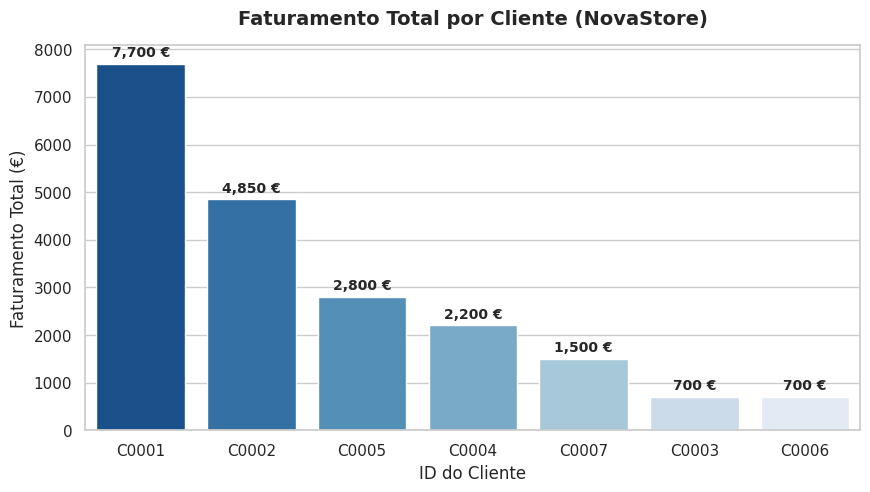

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo dos gráficos
sns.set_theme(style="whitegrid")

# 1. Agrupar o faturamento por cliente para visualizar os maiores compradores
faturamento_cliente = df_transacoes.groupby('ID_Cliente')['Valor_Total'].sum().reset_index()
faturamento_cliente = faturamento_cliente.sort_values(by='Valor_Total', ascending=False)

# 2. Criar a figura do gráfico
plt.figure(figsize=(10, 5))

# Criar um gráfico de barras com Seaborn
grafico = sns.barplot(
    data=faturamento_cliente,
    x='ID_Cliente',
    y='Valor_Total',
    palette='Blues_r'
)

# Adicionar títulos e rótulos aos eixos
plt.title('Faturamento Total por Cliente (NovaStore)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('ID do Cliente', fontsize=12)
plt.ylabel('Faturamento Total (€)', fontsize=12)

# Adicionar os valores numéricos por cima de cada barra
for p in grafico.patches:
    grafico.annotate(
        f'{p.get_height():,.0f} €',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 8),
        textcoords='offset points',
        fontsize=10, fontweight='bold'
    )

# Exibir o gráfico no Notebook
plt.show()